# InstellCa comparison

The extended-source irradiance of `hyperphase.irradiance` against InstellCa_3.0 (Sadh & Gavassino 2026, ApJ 997, 167; github.com/Mradumay137/InstellCa, MIT license), run through `InstellCa_3.0_exported.py`, a copy whose changes are marked `# MOD` (see its header). Both codes see the same geometry and stellar luminosity, so the comparison isolates the irradiance integral. In the fully illuminated zone the exact irradiance is $L\cos\alpha/(4\pi\rho^2)$ ($\rho$, $\alpha$: distance and zenith angle of the stellar centre) for any limb darkening, so an offset of InstellCa there is integration error; section 5 traces it to InstellCa's integration domain with an independent re-implementation, `instellca_transcription.py`.

In [1]:
import sys, os, subprocess, time, warnings
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter
from scipy.integrate import IntegrationWarning
from hyperphase.irradiance import insolation, insolation_fullyilluminated_hyperillum, insolation_penumbra_hyperillum, sigma
from hyperphase.validation import insolation_penumbra_hyperillum_approx
from hyperphase.bands import filter_lambda
from hyperphase.targets import hi_planets_by_name
import instellca_transcription as it

In [2]:
# Target planet and settings (as in the other notebooks)
planet = hi_planets_by_name("TOI-2431 b")
instrument = "MIRI/LRS"                       # only used for planet.summary(); the irradiance comparison is bolometric
u_bol = 0.6                                     # not the baseline DEFAULT_U_BOL: InstellCa supports only u = 0.6 and u = 0 (U_RUNS), and the comparison uses its u = 0.6 branch
U_RUNS = (0.6, 0.0)                           # InstellCa is run for both branches its code supports (u = 0.6 with its Teff x 1.0573 rescaling, and u = 0)
ORDER = 256                                   # Gauss-Legendre order of this work's penumbra quadrature for the comparison (default in insolation(): 64; convergence in Section 3)

planet.summary(print_params=True, eff_wavelength_range=filter_lambda(instrument))

=== TOI-2431 b ===
    name = TOI-2431 b
  period = 0.22419578
    incl = 74.0
     ecc = 0.0
       w = 90.0
      r1 = 0.02131
      r2 = 1.0
       R = 2.08
  T2_eff = 4109.0
    a_AU = 0.0063
     T14 = 0.748
    logg = 4.68
     feh = -0.02
--- derived ---
rp = r1/r2           = 0.0213
a  = R/r2            = 2.080
terminator_penumbra  = 60.6 deg
terminator_nightside = 118.1 deg
fraction_illuminated = 73.5 %  (fully illuminated: 25.4 %, penumbra: 48.1 %)
substellar_boost     = 2.08096 % (insolation), 0.51623 % (temperature)
approx_occ_depth     = 219.3 ppm


## 1. Run InstellCa

The interactive script runs with `INSTELLCA_MANUAL=1` (manual entry, no catalog folder), its prompts fed through `subprocess` once per value in `U_RUNS`; it writes its arrays to `outfiles/` (`RERUN = True` recomputes them). `outfiles/` is not part of the repository, so the first run computes every InstellCa run of this notebook. The units are converted so that InstellCa sees exactly the `a/R*` and `r1/r2` of `planet`; the eccentricity must be 0 (InstellCa evaluates 0 < e < 0.3 at periastron).

In [3]:
EXPORT_SCRIPT = os.path.abspath("InstellCa_3.0_exported.py")        # this folder's copy of InstellCa_3.0.py (see its header)
OUT_DIR = os.path.abspath("outfiles")                               # all run products: InstellCa text files and figures, comparison figures
os.makedirs(OUT_DIR, exist_ok=True)
RERUN = False                                                       # True: run InstellCa again even if the text files exist

# InstellCa's unit constants (from its source): invert them so that a/R* and r1/r2 are exactly the PlanetParams values
RSUN_IC, RJUP_IC, AU_IC = 6.955e8, 6.4e6 * 11.21, 1.496e11
rs1 = 1.0                                        # stellar radius [Rsun]
al1 = planet.R / planet.r2 * RSUN_IC / AU_IC     # semi-major axis [AU]
rp1 = planet.r1 / planet.r2 * RSUN_IC / RJUP_IC  # planet radius [RJ]
prompts = f"1\n{rp1:.10f}\n{rs1}\n{planet.T2_eff:g}\n{al1:.12f}\n0\n{planet.name}\n"   # manual mode (INSTELLCA_MANUAL=1)

print(f"InstellCa inputs: Rp = {rp1:.10f} RJ, Rs = {rs1} Rsun, Teff = {planet.T2_eff:g} K, a = {al1:.12f} AU, e = 0")
print(f"check: a/R* = {al1 * AU_IC / (rs1 * RSUN_IC):.8f} (PlanetParams {planet.R / planet.r2:.8f}),  r1/r2 = {rp1 * RJUP_IC / (rs1 * RSUN_IC):.8f} (PlanetParams {planet.r1 / planet.r2:.8f})")

InstellCa inputs: Rp = 0.2065831986 RJ, Rs = 1.0 Rsun, Teff = 4109 K, a = 0.009670053476 AU, e = 0
check: a/R* = 2.08000000 (PlanetParams 2.08000000),  r1/r2 = 0.02131000 (PlanetParams 0.02131000)


In [4]:
def instellca_file(u, tag=""):
    return os.path.join(OUT_DIR, planet.name.replace(" ", "_") + f"_u{u:g}{tag}_instellca.txt")

def run_instellca(u, tag="", **knobs):
    """Runs InstellCa_3.0_exported.py for limb-darkening coefficient u. knobs: INSTELLCA_EPSREL / INSTELLCA_EPSABS / INSTELLCA_LIMIT
    (scipy.integrate.quad tolerances; original: scipy defaults) and INSTELLCA_NLAT (latitude points; original: 500)."""
    if os.path.exists(instellca_file(u, tag)) and not RERUN:
        print(f"u = {u}{', ' + tag if tag else ''}: using existing {os.path.basename(instellca_file(u, tag))}")
        return
    env = dict(os.environ, INSTELLCA_U=str(u), INSTELLCA_TAG=tag, MPLBACKEND="Agg", INSTELLCA_MANUAL="1",
               **{k: str(v) for k, v in knobs.items()})
    t0 = time.perf_counter()
    res = subprocess.run([sys.executable, EXPORT_SCRIPT], input=prompts, text=True, capture_output=True, env=env)
    tail = res.stdout.strip().splitlines()[-1] if res.stdout.strip() else res.stderr.strip()[-500:]
    print(f"u = {u}{', ' + tag if tag else ''}: exit code {res.returncode} after {time.perf_counter() - t0:.1f} s; InstellCa says: {tail!r}; wrote {os.path.basename(instellca_file(u, tag))}")

for u in U_RUNS:
    run_instellca(u)

u = 0.6: using existing TOI-2431_b_u0.6_instellca.txt
u = 0.0: using existing TOI-2431_b_u0_instellca.txt


## 2. Load the InstellCa arrays

Angle from the substellar point, extended-source and inverse-square irradiance, rescaled to the stellar luminosity of `planet`: InstellCa uses $\sigma$ = 5.67e-8 and, for u = 0.6, multiplies $T_{\rm eff}$ by 1.0573, which conserves the luminosity only to $1.0573^4(1-u/3)$.

In [5]:
SIGMA_IC = 5.67e-8   # Stefan-Boltzmann constant hard-coded in InstellCa; hyperphase.irradiance uses astropy's `sigma`

def lum_factor(u, geometric=True):
    """Luminosity of InstellCa's star in units of 4 pi r2^2 sigma T2_eff^4: the sigma value, and for the geometric model at u = 0.6
    additionally the Teff x 1.0573 rescaling (the inverse-square curve uses the unscaled Teff)."""
    return SIGMA_IC / sigma * ((1.0573 ** 4 * (1 - u / 3)) if (geometric and u == 0.6) else 1.0)

def load_instellca(u, tag=""):
    """Angle from the substellar point [rad, >= 0], InstellCa's geometric (extended-source) irradiance and its inverse-square
    irradiance [W/m^2], both rescaled to the stellar luminosity of `planet`."""
    deg, geo_kw, inv_kw = np.loadtxt(instellca_file(u, tag), unpack=True)
    return np.radians(np.abs(deg)), geo_kw * 1e3 / lum_factor(u), inv_kw * 1e3 / lum_factor(u, geometric=False)

ic = {u: load_instellca(u) for u in U_RUNS}
for u, (gam, E_geo, E_inv) in ic.items():
    i0 = np.argmin(gam)
    print(f"u = {u}: {gam.size} points, |angle| up to {np.degrees(gam.max()):.2f} deg (true terminator {planet.terminator_nightside('deg'):.2f} deg); "
          f"closest to substellar point: {np.degrees(gam[i0]):.2f} deg, geometric {E_geo[i0]/1e3:.4f} kW/m2, inverse-square {E_inv[i0]/1e3:.4f} kW/m2")

u = 0.6: 500 points, |angle| up to 118.00 deg (true terminator 118.07 deg); closest to substellar point: 0.24 deg, geometric 3841.1469 kW/m2, inverse-square 3813.9109 kW/m2
u = 0.0: 500 points, |angle| up to 118.00 deg (true terminator 118.07 deg); closest to substellar point: 0.24 deg, geometric 3860.1043 kW/m2, inverse-square 3813.9109 kW/m2


## 3. This work on the same angles, and its numerical floor

`hyperillum` is closed-form in the fully illuminated zone and a Gauss–Legendre quadrature in the penumbra. Its convergence with `order` against an independent adaptive quadrature over the exact visible domain (`it.exact_E_quad`) gives the floor of this work; the comparison uses `ORDER`. The second cell checks the closed form and prints the offsets of InstellCa.

In [6]:
gp1, gp2 = planet.terminator_penumbra(), planet.terminator_nightside()
gam = ic[u_bol][0]
pen = (gam >= gp1) & (gam < gp2)
gam_pen = np.unique(gam[pen])
E_sub = float(insolation(np.array([0.]), planet, "hyperillum", u_bol=u_bol)[0])
geo = it.Geo(planet.R / planet.r2, planet.r1 / planet.r2, planet.T2_eff)
t0 = time.perf_counter()
E_ref = np.array([it.exact_E_quad(float(la), geo, u_bol) for la in gam_pen]) / lum_factor(u_bol)
print(f"independent reference on {gam_pen.size} penumbra angles: {time.perf_counter() - t0:.1f} s")
print(f"{'order':>6} {'max |rel. diff| (<= 110 deg)':>30} {'max |diff| / E_substellar':>28}")
for order in (16, 32, 64, 128, 256, 512, 1024):
    E_o = insolation_penumbra_hyperillum(gam_pen, planet, u_bol=u_bol, order=order)
    inner = gam_pen <= np.radians(110.)
    print(f"{order:6d} {np.max(np.abs(E_o[inner] / E_ref[inner] - 1)):30.1e} {np.max(np.abs(E_o - E_ref)) / E_sub:28.1e}")
print(f"-> comparison below uses order = {ORDER}; the fully illuminated zone is closed-form (checked against the analytic expression in the next cell)")

def hyperillum(gam, u, order=ORDER):
    """insolation(..., 'hyperillum') with a selectable penumbra quadrature order."""
    E = insolation(gam, planet, "hyperillum", u_bol=u)
    m = (gam >= gp1) & (gam < gp2)
    E[m] = insolation_penumbra_hyperillum(gam[m], planet, u_bol=u, order=order)
    return E

independent reference on 184 penumbra angles: 2.4 s
 order   max |rel. diff| (<= 110 deg)    max |diff| / E_substellar
    16                        5.5e-03                      5.5e-05
    32                        1.2e-03                      9.8e-06
    64                        2.2e-04                      1.8e-06
   128                        4.7e-05                      2.5e-07


   256                        8.0e-06                      5.5e-08


   512                        1.3e-06                      1.1e-08


  1024                        1.8e-07                      1.1e-08
-> comparison below uses order = 256; the fully illuminated zone is closed-form (checked against the analytic expression in the next cell)


In [7]:
def analytic_fully_illuminated(gam):
    # L cos(alpha) / (4 pi rho^2), rho and alpha the distance and zenith angle of the stellar centre: exact in the fully illuminated zone for any limb darkening
    rho = np.sqrt(planet.R ** 2 + planet.r1 ** 2 - 2 * planet.R * planet.r1 * np.cos(gam))
    return planet.r2 ** 2 * sigma * planet.T2_eff ** 4 * (planet.R * np.cos(gam) - planet.r1) / rho ** 3

mine = {u: dict(hyperillum=hyperillum(gam, u), naive=insolation(gam, planet, "naive")) for u, (gam, _, _) in ic.items()}

for u, (gam, E_geo, E_inv) in ic.items():
    E_hi = mine[u]["hyperillum"]
    fi, pen = gam < gp1, (gam >= gp1) & (gam < gp2)
    r_fi = E_geo[fi] / E_hi[fi] - 1
    inner = pen & (gam <= np.radians(110.))     # the relative difference diverges in the last degrees before the terminator, where the true irradiance -> 0
    print(f"u = {u}:")
    print(f"   this work vs analytic (fully illuminated zone):            max |rel. diff| = {np.max(np.abs(E_hi[fi] / analytic_fully_illuminated(gam[fi]) - 1)):.1e}")
    print(f"   InstellCa inverse-square vs this work (fully illuminated): max |rel. diff| = {np.max(np.abs(E_inv[fi] / E_hi[fi] - 1)):.1e}")
    print(f"   InstellCa geometric vs this work: fully illuminated zone mean {np.mean(r_fi):+.3%} (min {r_fi.min():+.3%}, max {r_fi.max():+.3%}); "
          f"penumbra up to 110 deg {np.min(E_geo[inner] / E_hi[inner] - 1):+.3%} .. {np.max(E_geo[inner] / E_hi[inner] - 1):+.3%}")
    for d in (float(np.degrees(gp1)), 90., 100., 110.):
        i = np.argmin(np.abs(np.degrees(gam) - d))
        print(f"   at {np.degrees(gam[i]):6.2f} deg: InstellCa geometric / this work - 1 = {E_geo[i] / E_hi[i] - 1:+.3%}")
    i0 = np.argmin(gam)
    print(f"   naive / hyperillum - 1 at the substellar point = {mine[u]['naive'][i0] / E_hi[i0] - 1:+.3%}  (finite-planet-radius factor: {(planet.R / (planet.R - planet.r1)) ** -2 - 1:+.3%})")

u = 0.6:
   this work vs analytic (fully illuminated zone):            max |rel. diff| = 5.6e-16
   InstellCa inverse-square vs this work (fully illuminated): max |rel. diff| = 1.3e-11
   InstellCa geometric vs this work: fully illuminated zone mean +0.708% (min +0.694%, max +0.714%); penumbra up to 110 deg +0.656% .. +10.757%
   at  60.77 deg: InstellCa geometric / this work - 1 = +0.674%
   at  90.10 deg: InstellCa geometric / this work - 1 = +1.530%
   at 100.03 deg: InstellCa geometric / this work - 1 = +3.020%
   at 109.96 deg: InstellCa geometric / this work - 1 = +10.757%
   naive / hyperillum - 1 at the substellar point = -2.039%  (finite-planet-radius factor: -2.039%)
u = 0.0:
   this work vs analytic (fully illuminated zone):            max |rel. diff| = 5.6e-16
   InstellCa inverse-square vs this work (fully illuminated): max |rel. diff| = 1.3e-11
   InstellCa geometric vs this work: fully illuminated zone mean +1.202% (min +1.182%, max +1.211%); penumbra up to 110 deg +1.11

## 4. Comparison figure

Top: irradiance at `u_bol` with the illumination zones; InstellCa as points on its own grid. Bottom: the relative difference to this work for both InstellCa runs and for InstellCa's inverse-square (point-source) curve. Saved to `outfiles/`.

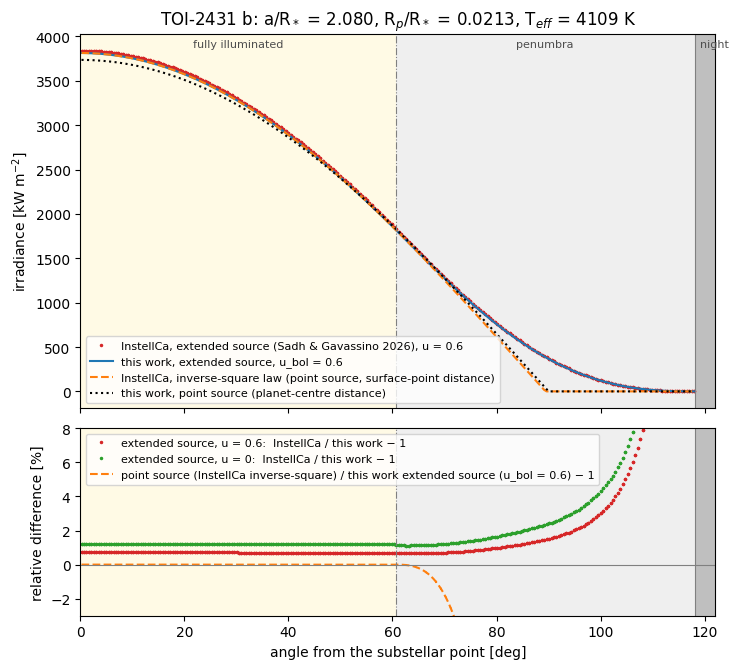

In [8]:
def shade_zones(ax, label_y=None, fontsize=8):
    d1, d2 = np.degrees(gp1), np.degrees(gp2)
    ax.axvspan(0, d1, color="gold", alpha=0.10, lw=0); ax.axvspan(d1, d2, color="gray", alpha=0.12, lw=0); ax.axvspan(d2, 180, color="k", alpha=0.25, lw=0)
    ax.axvline(d1, color="gray", lw=0.8, ls="-."); ax.axvline(d2, color="gray", lw=0.8)
    if label_y is not None:
        for xc, txt in ((d1 / 2, "fully illuminated"), ((d1 + d2) / 2, "penumbra"), (d2 + 1.0, "night")):
            ax.text(xc, label_y, txt, ha="center" if txt != "night" else "left", va="top", fontsize=fontsize, color="0.3")

gam, E_geo, E_inv = ic[u_bol]
deg = np.degrees(gam); order_ = np.argsort(deg)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7.5, 6.8), gridspec_kw=dict(height_ratios=[3, 1.5]))
ax1.plot(deg, E_geo / 1e3, ".", ms=3, color="C3", label=f"InstellCa, extended source (Sadh & Gavassino 2026), u = {u_bol:g}")
ax1.plot(deg[order_], mine[u_bol]["hyperillum"][order_] / 1e3, "-", color="C0", label=f"this work, extended source, u_bol = {u_bol:g}")
ax1.plot(deg[order_], E_inv[order_] / 1e3, "--", color="C1", label="InstellCa, inverse-square law (point source, surface-point distance)")
ax1.plot(deg[order_], mine[u_bol]["naive"][order_] / 1e3, ":", color="k", label="this work, point source (planet-centre distance)")
ax1.set_ylabel("irradiance [kW m$^{-2}$]")
ax1.set_title(f"{planet.name}: a/R$_*$ = {planet.R / planet.r2:.3f}, R$_p$/R$_*$ = {planet.r1 / planet.r2:.4f}, T$_{{eff}}$ = {planet.T2_eff:g} K")
ax1.legend(fontsize=8, loc="lower left")
shade_zones(ax1, label_y=ax1.get_ylim()[1] * 0.985)
for u, col in zip(U_RUNS, ("C3", "C2")):
    g_u, geo_u, _ = ic[u]
    ax2.plot(np.degrees(g_u), 100 * (geo_u / mine[u]["hyperillum"] - 1), ".", ms=3, color=col, label=f"extended source, u = {u:g}:  InstellCa / this work − 1")
ax2.plot(deg[order_], 100 * (E_inv[order_] / mine[u_bol]["hyperillum"][order_] - 1), "--", color="C1", label=f"point source (InstellCa inverse-square) / this work extended source (u_bol = {u_bol:g}) − 1")
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_ylim(-3, 8); ax2.set_ylabel("relative difference [%]"); ax2.set_xlabel("angle from the substellar point [deg]")
ax2.legend(fontsize=8, loc="upper left")
shade_zones(ax2)
ax1.set_xlim(0, np.degrees(gp2) + 4)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"InstellCa_comparison_{planet.name.replace(' ', '_')}.pdf"))
fig.savefig(os.path.join(OUT_DIR, f"InstellCa_comparison_{planet.name.replace(' ', '_')}.png"), dpi=200)
plt.show()

## 5. Where the InstellCa offset comes from

InstellCa integrates over a rectangle in stellar latitude × longitude (its eqs. B7–B10) whose corners lie beyond the stellar limb, and takes `abs()` of both cosines, so these invisible elements count instead of dropping out (panel (a) of section 6); Sadh & Gavassino attribute the < 1 % offset to resolution. 5.1 re-runs InstellCa with tighter tolerances and a denser grid, which leaves a domain error unchanged; 5.2 evaluates InstellCa's integrand (in vector form) on (a) InstellCa's rectangle, (b) the rectangle without the invisible elements and (c) the true domain, where a domain error vanishes in (b) and (c).

In [9]:
# 5.1 InstellCa's own dials: quadrature tolerances and latitude-grid density (same u as the comparison figure)
# the tight-tolerance run costs ~1 s per latitude point (adaptive subdivision around the abs() kinks), so it is done on 120 points
DIALS = {"": {}, "_quad1e-8_nlat120": dict(INSTELLCA_EPSREL=1e-8, INSTELLCA_EPSABS=0, INSTELLCA_LIMIT=200, INSTELLCA_NLAT=120), "_nlat2000": dict(INSTELLCA_NLAT=2000)}
for tag, knobs in DIALS.items():
    run_instellca(u_bol, tag, **knobs)
dial = {tag: load_instellca(u_bol, tag) for tag in DIALS}
print(f"\nInstellCa (u = {u_bol:g}) relative to this work:")
print(f"{'run':>14} {'points':>7} {'fully illuminated zone: mean':>30} {'spread (max-min)':>18} {'at 90 deg':>11} {'at 100 deg':>11}")
for tag, (g_t, geo_t, _) in dial.items():
    E_hi_t = hyperillum(g_t, u_bol)
    r = geo_t / E_hi_t - 1
    fi_t = g_t < gp1
    i90, i100 = np.argmin(np.abs(np.degrees(g_t) - 90)), np.argmin(np.abs(np.degrees(g_t) - 100))
    print(f"{tag or 'as published':>14} {g_t.size:7d} {np.mean(r[fi_t]):+30.4%} {np.ptp(r[fi_t]):18.4%} {r[i90]:+11.3%} {r[i100]:+11.3%}")

u = 0.6: using existing TOI-2431_b_u0.6_instellca.txt
u = 0.6, _quad1e-8_nlat120: using existing TOI-2431_b_u0.6_quad1e-8_nlat120_instellca.txt
u = 0.6, _nlat2000: using existing TOI-2431_b_u0.6_nlat2000_instellca.txt

InstellCa (u = 0.6) relative to this work:
           run  points   fully illuminated zone: mean   spread (max-min)   at 90 deg  at 100 deg
  as published     500                       +0.7083%            0.0200%     +1.530%     +3.020%
_quad1e-8_nlat120     120                       +0.7082%            0.0220%     +1.541%     +3.042%
     _nlat2000    2000                       +0.7083%            0.0202%     +1.524%     +3.027%


In [10]:
# 5.2 Transcription: (i) does it reproduce the script? (ii) what happens when the integration domain is corrected?
gam, E_geo, E_inv = ic[u_bol]
idx = np.argsort(gam)[::25]                                         # every 25th grid point
E_tr = np.array([it.instellca_E(float(gam[i]), geo, u_bol) for i in idx]) / lum_factor(u_bol)
print(f"transcription vs InstellCa script output at {idx.size} angles: max |rel. diff| = {np.max(np.abs(E_tr / E_geo[idx] - 1)):.1e}  (the inputs are rounded to 10 digits)")

test_deg = [0.5, 30., 55., float(np.degrees(gp1)) + 2, 80., 90., 100., 110.]
print(f"\n{'angle [deg]':>11} | {'InstellCa script':>16} {'(a) rectangle + abs':>20} {'(b) rectangle, masked':>22} {'(c) true domain':>16}   (each: value / this work - 1)")
variants = {}
for d in test_deg:
    la = float(np.radians(d))
    E_hi_d = float(hyperillum(np.array([la]), u_bol)[0])
    i_near = np.argmin(np.abs(gam - la))
    with warnings.catch_warnings():   # the rectangle integrands have kinks (abs) or jumps (mask) inside the domain, where scipy reports that roundoff keeps it from certifying epsrel = 1e-10
        warnings.simplefilter("ignore", IntegrationWarning)
        va = it.instellca_variant(la, geo, u_bol, "box", True) / lum_factor(u_bol)
        vb = it.instellca_variant(la, geo, u_bol, "box_masked") / lum_factor(u_bol)
    vc = it.instellca_variant(la, geo, u_bol, "exact") / lum_factor(u_bol)
    variants[d] = (va / E_hi_d - 1, vb / E_hi_d - 1, vc / E_hi_d - 1)
    script = E_geo[i_near] / mine[u_bol]["hyperillum"][i_near] - 1
    print(f"{d:11.2f} | {script:+16.4%} {va / E_hi_d - 1:+20.4%} {vb / E_hi_d - 1:+22.2e} {vc / E_hi_d - 1:+16.1e}")
print("(the script column is the nearest grid point, computed with scipy's default tolerances; (a)-(c) use epsrel = 1e-10)")

transcription vs InstellCa script output at 20 angles: max |rel. diff| = 9.7e-11  (the inputs are rounded to 10 digits)

angle [deg] | InstellCa script  (a) rectangle + abs  (b) rectangle, masked  (c) true domain   (each: value / this work - 1)


       0.50 |         +0.7141%             +0.7147%              -3.49e-08         +2.2e-16


      30.00 |         +0.7103%             +0.7106%              -3.48e-08         -4.4e-16


      55.00 |         +0.6987%             +0.6980%              -3.48e-08         -6.7e-16


      62.59 |         +0.6560%             +0.6559%              -1.06e-04         -5.6e-09


      80.00 |         +0.9828%             +0.9701%              -5.27e-04         +1.5e-07


      90.00 |         +1.5295%             +1.5240%              -3.35e-09         +5.3e-09


     100.00 |         +3.0195%             +2.9998%              +9.31e-07         +9.3e-07


     110.00 |        +10.7573%            +10.7883%              -4.75e-06         -4.7e-06
(the script column is the nearest grid point, computed with scipy's default tolerances; (a)-(c) use epsrel = 1e-10)


## 6. Summary figure

(a) InstellCa's integration domain for a point in the fully illuminated zone. (b) The published treatments with limb darkening relative to this work, colour = $u_{\rm bol}$: InstellCa (points; its inverse-square curve dashed) and the closed form of Kopal (1954) (lines; eqs. 43–48 with the sign of $\lambda$ corrected, `insolation_penumbra_hyperillum_approx`). Kang et al. (2023) and Carter et al. (2024) would lie on zero for $u_{\rm bol} = 0$ and are not drawn. Saved to `outfiles/`.

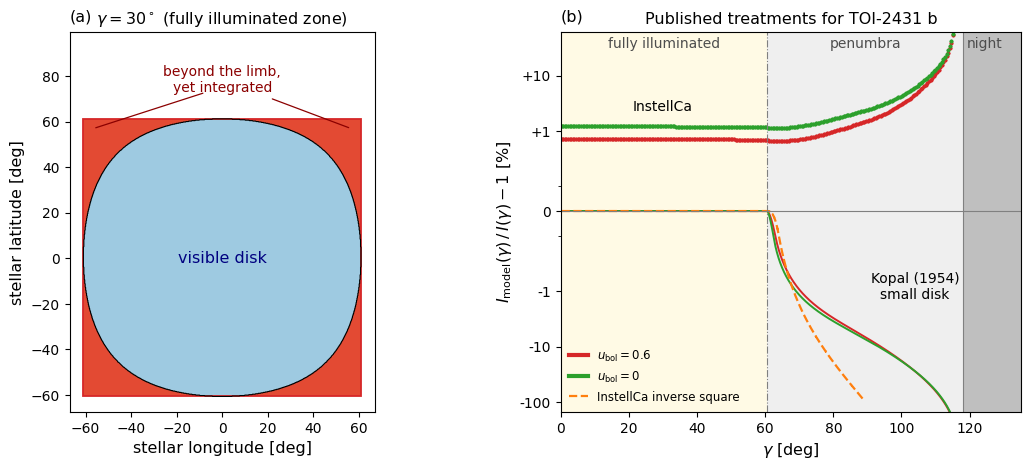

In [11]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(10.5, 4.8), gridspec_kw=dict(width_ratios=[1, 1.35]))

# --- left: InstellCa's integration rectangle vs the visible disk, for a point in the fully illuminated zone
d_sketch = 30.
m = it.domain_masks(float(np.radians(d_sketch)), geo, n=700)
cat = np.zeros(m["true"].shape, dtype=int)
cat[m["true"] & m["box"]] = 1; cat[m["box"] & ~m["true"]] = 2; cat[m["true"] & ~m["box"]] = 3
axL.pcolormesh(np.degrees(m["x"]), np.degrees(m["th"]), cat, cmap=ListedColormap(["white", "#9ecae1", "#e34a33", "#fdae6b"]), vmin=-0.5, vmax=3.5, shading="auto", rasterized=True)
axL.contour(np.degrees(m["x"]), np.degrees(m["th"]), m["cap"].astype(float), levels=[0.5], colors="k", linewidths=0.8)
axL.add_patch(plt.Rectangle((-np.degrees(m["y3"]), np.degrees(m["ll"])), 2 * np.degrees(m["y3"]), np.degrees(m["ul"] - m["ll"]), fill=False, ec="C3", lw=1.3))
axL.text(0, 0, "visible disk", ha="center", va="center", fontsize=11.5, color="navy")
xr, yr = np.degrees(m["y3"]), np.degrees(m["ul"])
axL.annotate("beyond the limb,\nyet integrated", xy=(0.93 * xr, 0.93 * yr), xytext=(0.0, 1.17 * yr), ha="center", va="bottom", fontsize=10, color="darkred",
             arrowprops=dict(arrowstyle="-", color="darkred", lw=0.9), annotation_clip=False)
axL.annotate("", xy=(-0.93 * xr, 0.93 * yr), xytext=(-0.12 * xr, 1.19 * yr), arrowprops=dict(arrowstyle="-", color="darkred", lw=0.9), annotation_clip=False)
axL.set_ylim(-1.1 * yr, 1.62 * yr); axL.set_xlim(-1.1 * xr, 1.1 * xr)
axL.set_xlabel("stellar longitude [deg]", fontsize=11.5); axL.set_ylabel("stellar latitude [deg]", fontsize=11.5)
axL.set_title(f"$\\gamma = {d_sketch:g}^\\circ$ (fully illuminated zone)", fontsize=11.5)
axL.tick_params(labelsize=10); axL.set_aspect("equal")

# --- right: published treatments relative to this work
# InstellCa (Sadh & Gavassino 2026): points on its own grid. Kopal (1954): his closed forms (eqs. 43-48, sign of lambda corrected;
# insolation_penumbra_hyperillum_approx) in the penumbra, his exact eq. (34) in the fully illuminated zone. Colour = u_bol; InstellCa (points) lies above zero, Kopal (lines) below.
# The y axis is symmetric-logarithmic (linear within +-0.1 %): InstellCa's +0.7 % dayside offset and Kopal's -100 % near the terminator
# differ by two orders of magnitude.
gam, E_geo, E_inv = ic[u_bol]
deg = np.degrees(gam); order_ = np.argsort(deg)
g_k = np.linspace(0., gp2, 3000, endpoint=False)            # Kopal on a fine grid up to (excluding) the terminator
fi_k = g_k < gp1
U_COL = {0.6: "C3", 0.0: "C2"}
for u in U_RUNS:
    g_u, geo_u, _ = ic[u]
    axR.plot(np.degrees(g_u), 100 * (geo_u / mine[u]["hyperillum"] - 1), ".", ms=3.5, color=U_COL[u])
    E_k = np.where(fi_k, insolation_fullyilluminated_hyperillum(g_k, planet), insolation_penumbra_hyperillum_approx(g_k, planet, u_bol=u))
    axR.plot(np.degrees(g_k), 100 * (E_k / hyperillum(g_k, u) - 1), "-", color=U_COL[u], lw=1.4)
inv_pos = E_inv[order_] > 0                                  # the inverse-square curve is zero beyond alpha = 90 deg (-100 %): not drawn there
axR.plot(deg[order_][inv_pos], 100 * (E_inv[order_][inv_pos] / mine[u_bol]["hyperillum"][order_][inv_pos] - 1), "--", color="C1", lw=1.6)
axR.axhline(0, color="gray", lw=0.8)
axR.set_yscale("symlog", linthresh=0.1, linscale=0.4)
axR.set_ylim(-150, 60)
axR.yaxis.set_major_locator(FixedLocator([-100, -10, -1, 0, 1, 10]))
axR.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+g}" if v else "0"))
shade_zones(axR, label_y=50, fontsize=10)
axR.set_xlim(0, np.degrees(gp2) + 17)                      # wide enough for the "night" label
axR.set_xlabel("$\\gamma$ [deg]", fontsize=11.5); axR.set_ylabel("$I_{\\rm model}(\\gamma)\\,/\\,I(\\gamma) - 1$ [%]", fontsize=11.5)
axR.set_title(f"Published treatments for {planet.name}", fontsize=11.5)
# the two treatments are labelled on the plot (InstellCa above zero, Kopal's approximation below); the legend keys u_bol and the dashed curve
axR.text(30, 2.0, "InstellCa", ha="center", va="bottom", fontsize=10)
axR.text(104, -0.45, "Kopal (1954)\nsmall disk", ha="center", va="top", fontsize=10)
handles = [Line2D([], [], ls="-", lw=3, color=U_COL[0.6], label="$u_{\\rm bol} = 0.6$"),
           Line2D([], [], ls="-", lw=3, color=U_COL[0.0], label="$u_{\\rm bol} = 0$"),
           Line2D([], [], ls="--", lw=1.6, color="C1", label="InstellCa inverse square")]
axR.legend(handles=handles, fontsize=8.5, loc="lower left", frameon=False, ncol=1, handlelength=1.6, borderaxespad=0.3)
axR.tick_params(labelsize=10)
for ax, lab in ((axL, "(a)"), (axR, "(b)")):
    ax.text(0., 1.02, lab, transform=ax.transAxes, ha="left", va="bottom", fontsize=11.5)
fig.tight_layout(w_pad=3.0)
fig.subplots_adjust(wspace=0.42)                             # gap between the panels
fig.savefig(os.path.join(OUT_DIR, f"InstellCa_paper_{planet.name.replace(' ', '_')}.pdf"), dpi=600)   # dpi applies to the rasterized domain map only; the rest is vector
fig.savefig(os.path.join(OUT_DIR, f"InstellCa_paper_{planet.name.replace(' ', '_')}.png"), dpi=600)
plt.show()